<a href="https://colab.research.google.com/github/JuanitaRozo/Redes_Neuronales_III/blob/main/Practica1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Paso 1: Importación de librerías y descarga de datos

En esta celda inicial, realizamos las siguientes acciones esenciales para preparar el entorno de trabajo:

* **Importación de herramientas clave:** Cargamos numpy para el manejo de vectores, matplotlib.pyplot para la visualización de datos y gráficos, y tensorflow como el framework principal para la creación de la red neuronal.
* **División de datos:** Importamos train_test_split de la librería Scikit-Learn para repartir nuestros datos.
* **Verificación del sistema:** Comprobamos la versión de TensorFlow instalada y si disponemos de aceleración por GPU para agilizar el entrenamiento.
* **Carga del dataset:** Descargamos e importamos el conjunto de datos **Fashion-MNIST**, el cual contiene 70,000 imágenes de prendas de vestir en escala de grises de 28x28 píxeles. El dataset ya viene pre-dividido por defecto en un conjunto de entrenamiento (60,000 imágenes) y otro de prueba (10,000 imágenes).

In [ ]:
#se importan las librerías y cargamos los datos


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

print("Versión de TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))


(x_total, y_total), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Datos originales de entrenamiento:", x_total.shape)
print("Etiquetas de entrenamiento:", y_total.shape)
print("Datos originales de prueba:", x_test.shape)
print("Etiquetas de prueba:", y_test.shape)


Versión de TensorFlow: 2.21.0
GPU disponible: []
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos originales de entrenamiento: (60000, 28, 28)
Etiquetas de entrenamiento: (60000,)
Datos originales de prueba: (10000, 28, 28)
Etiquetas de prueba: (10000,)


### Paso 2: Creación del conjunto de validación y Normalización

En esta sección preparamos los datos numéricos antes de alimentarlos a la red neuronal:

1. **División en entrenamiento y desarrollo (Validación):** Usamos el conjunto original de entrenamiento y tomamos un 10% (6,000 imágenes) para crear un conjunto de validación (x_dev, y_dev). Esto nos servirá para monitorizar el rendimiento del modelo durante el entrenamiento sin sesgarnos con los datos de prueba (test).
2. **Normalización (Escalado de píxeles):** Las imágenes originales representaban la intensidad de cada píxel en valores enteros de 0 a 255. Dividimos todos los valores entre 255.0 para convertirlos a un tipo decimal (float32) dentro del rango [0.0, 1.0]. Esto mejora drásticamente la estabilidad y velocidad de convergencia de los algoritmos de optimización.

In [ ]:
# vamos a normalizar y dividir los datos ya que las imágenes originales contienen valores de píxeles entre 0 y 255
# al dividirlos entre 255, los transformamos al intervalo de 0 a 1, lo que facilita el entrenamiento de la red


# Separar el conjunto de entrenamiento original
x_train, x_dev, y_train, y_dev = train_test_split(
    x_total,
    y_total,
    test_size=0.10,
    random_state=42,
    stratify=y_total
)

# Convertir píxeles a valores entre 0 y 1
x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)

print("Valor mínimo:", x_train.min())
print("Valor máximo:", x_train.max())


Train: (54000, 28, 28) (54000,)
Dev: (6000, 28, 28) (6000,)
Test: (10000, 28, 28) (10000,)
Valor mínimo: 0.0
Valor máximo: 1.0


El parámetro **stratify=y_total** conserva la proporción de las clases al realizar la separación

**random_state=42** permite reproducir la misma división en ejecuciones posteriores

### Paso 3: Visualización de muestras de imágenes

Antes de modelar, es crucial inspeccionar los datos visualmente para comprender a qué nos enfrentamos:

* **Mapeo de etiquetas:** Definimos una lista llamada class_names para traducir las etiquetas numéricas (que van de 0 a 9) a nombres de categorías de ropa en español (por ejemplo, "Camiseta", "Pantalón", etc.).
* **Gráfico de imágenes:** Dibujamos una cuadrícula de 2 filas y 5 columnas donde mostramos las primeras 10 imágenes del conjunto de entrenamiento en escala de grises y colocamos como título su respectiva etiqueta textual para verificar que los datos se hayan cargado de forma correcta.

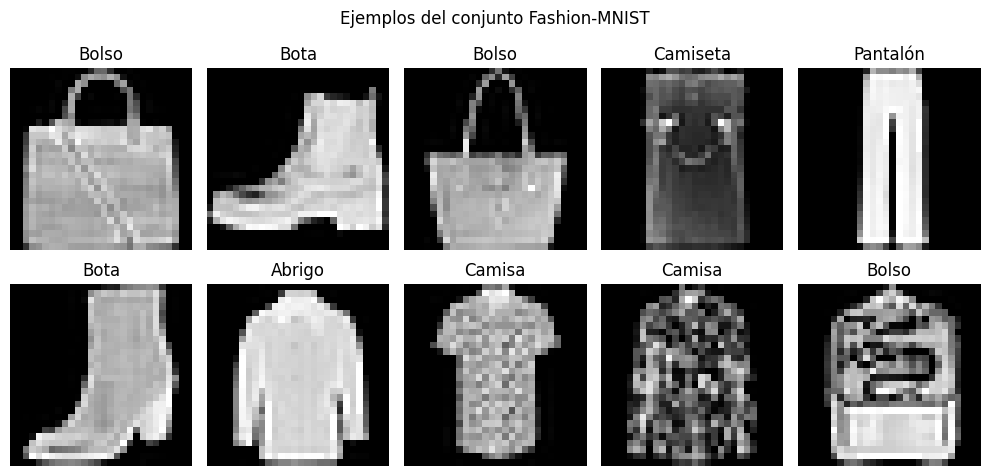

In [ ]:
#Visualizacion de las imagenes


class_names = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Zapatilla", "Bolso", "Bota"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Ejemplos del conjunto Fashion-MNIST")
plt.tight_layout()
plt.show()


### Paso 4: Análisis de la distribución de clases

Para garantizar un entrenamiento óptimo, es importante verificar si las categorías están balanceadas:

* **Conteo de clases:** Usamos la función np.unique para contar cuántas imágenes pertenecen a cada una de las 10 categorías en nuestro conjunto de entrenamiento.
* **Histograma de frecuencias:** Creamos un gráfico de barras que muestra la cantidad de imágenes por cada prenda. Al estar perfectamente niveladas (con exactamente 5,400 imágenes para cada categoría), confirmamos que disponemos de un **dataset balanceado**, lo que evita que el modelo aprenda a priorizar una clase sobre otra.

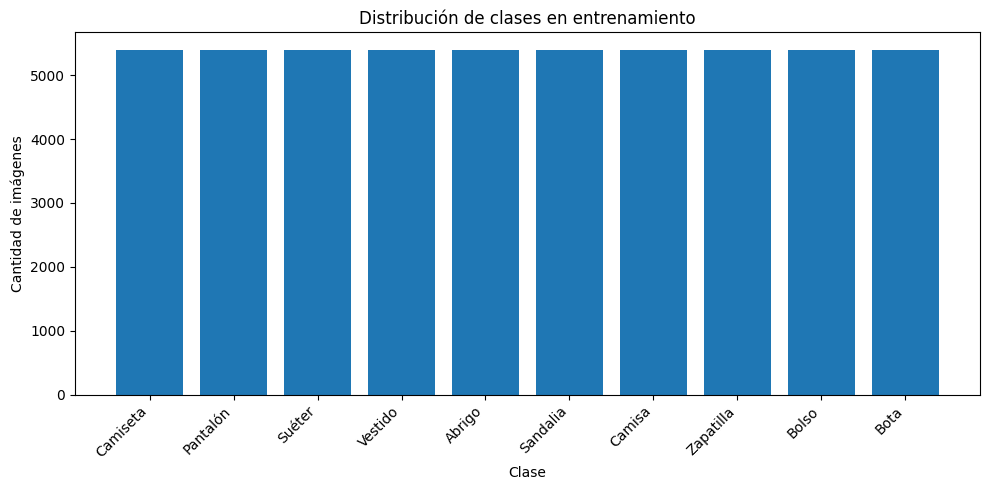

Total de imágenes de entrenamiento: 54000
Número de clases: 10


In [ ]:
#comprobamos la distribucion de la clase


clases, cantidades = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar([class_names[i] for i in clases], cantidades)
plt.title("Distribución de clases en entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Total de imágenes de entrenamiento:", len(y_train))
print("Número de clases:", len(np.unique(y_train)))
